# Book-Crossing: Exploratory Data Analysis

This notebook profiles the canonical data produced by `data_loader.py`. It is an engineering and modeling artifact: findings here inform cleaning rules, the collaborative-filtering representation, baseline design, and evaluation. It is not a slide deck or meeting-only document.

The source has no event timestamps. Rating `0` is an implicit interaction; `1`–`10` are explicit ratings. Keep these signals distinguishable throughout the analysis.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))

from book_recommendation.data_loader import load_book_crossing_data, report_as_dict

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 120)
plt.style.use('seaborn-v0_8-whitegrid')

In [2]:
data = load_book_crossing_data(ROOT / 'data' / 'raw')
users, books, ratings = data.users, data.books, data.ratings

print('Data quality report')
display(pd.Series(report_as_dict(data.report), name='value').to_frame())
print(f'Canonical shapes: users={users.shape}, books={books.shape}, ratings={ratings.shape}')
display(books.head())
display(ratings.head())

Data quality report


,value
users_source_rows,278858
books_source_rows,271360
ratings_source_rows,1149780
users_missing_id_removed,0
books_missing_id_or_title_removed,0
ratings_missing_key_removed,0
duplicate_users_removed,0
duplicate_books_removed,1
duplicate_user_book_ratings_removed,0
invalid_ratings_removed,0


Canonical shapes: users=(278858, 1), books=(271359, 5), ratings=(1031139, 4)


,book_id,title,authors,publisher,publication_year
0,0195153448,Classical Mythology,Mark P. O. Morford,Oxford University Press,2002
1,0002005018,Clara Callan,Richard Bruce Wright,HarperFlamingo Canada,2001
2,0060973129,Decision in Normandy,Carlo D'Este,HarperPerennial,1991
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,Farrar Straus Giroux,1999
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,W. W. Norton &amp; Company,1999


,user_id,book_id,rating,is_explicit
0,276725,034545104X,0,False
1,276726,0155061224,5,True
2,276727,0446520802,0,False
3,276729,052165615X,3,True
4,276729,0521795028,6,True


## Rating semantics and distribution

Check the split between implicit zeros and explicit ratings before choosing model inputs. A zero must not be averaged as if it were a user's explicit score.

,interactions
is_explicit,
implicit (0),647296
explicit (1-10),383843


,explicit_rating
count,383843.000000
mean,7.626689
std,1.841352
min,1.000000
25%,7.000000
50%,8.000000
75%,9.000000
max,10.000000


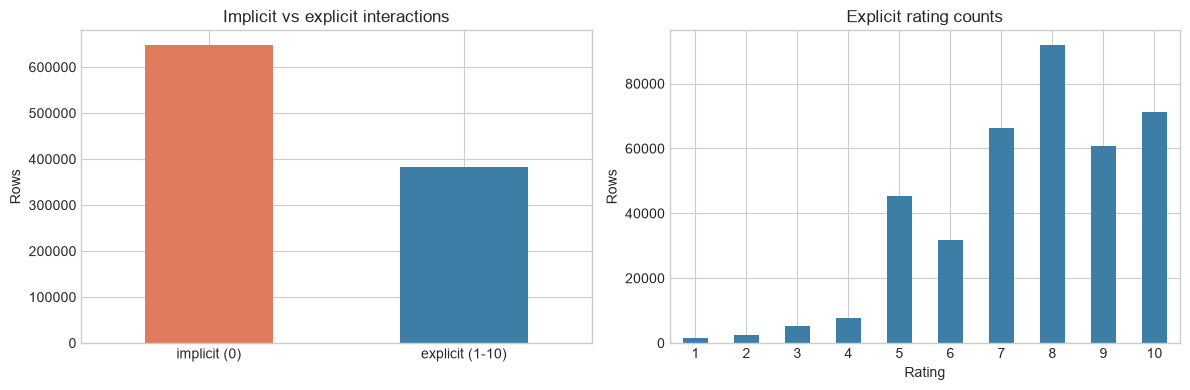

In [3]:
rating_summary = ratings['is_explicit'].value_counts().rename(index={False: 'implicit (0)', True: 'explicit (1-10)'})
display(rating_summary.to_frame('interactions'))

explicit = ratings.loc[ratings['is_explicit'], 'rating']
display(explicit.describe().to_frame('explicit_rating'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rating_summary.plot.bar(ax=axes[0], color=['#e07a5f', '#3d7ea6'], rot=0)
axes[0].set(title='Implicit vs explicit interactions', xlabel='', ylabel='Rows')
explicit.value_counts().sort_index().plot.bar(ax=axes[1], color='#3d7ea6', rot=0)
axes[1].set(title='Explicit rating counts', xlabel='Rating', ylabel='Rows')
plt.tight_layout()

## User and item activity

Long-tailed activity is common in recommendation data. Inspect it before selecting minimum-history filters or choosing a scalable nearest-neighbor strategy. The log axes make the tail visible.

,interaction_count
count,92106.000000
mean,11.195134
std,88.685731
min,1.000000
50%,1.000000
90%,13.000000
95%,31.000000
99%,180.000000
max,11144.000000


,interaction_count
count,270151.000000
mean,3.816899
std,13.811691
min,1.000000
50%,1.000000
90%,7.000000
95%,12.000000
99%,42.000000
max,2502.000000


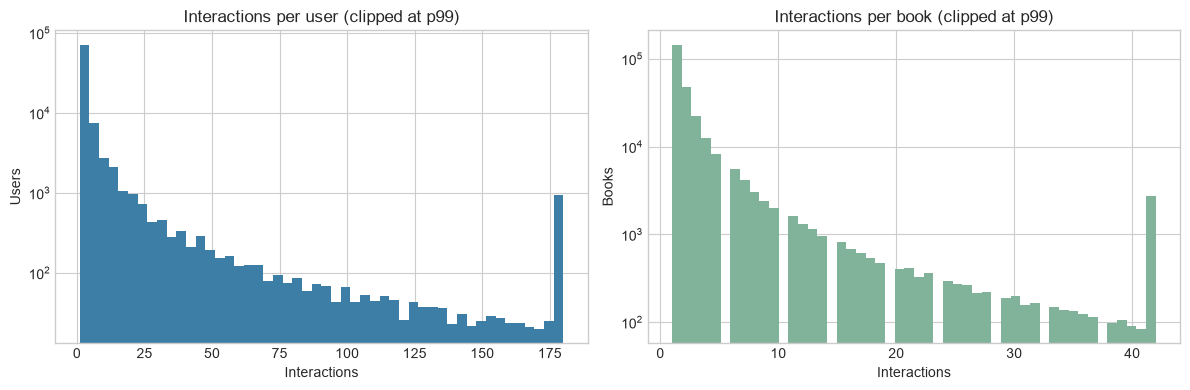

In [4]:
user_activity = ratings.groupby('user_id').size().rename('interaction_count')
book_activity = ratings.groupby('book_id').size().rename('interaction_count')
explicit_book_activity = ratings.loc[ratings['is_explicit']].groupby('book_id').size().rename('explicit_rating_count')
display(user_activity.describe(percentiles=[.5, .9, .95, .99]).to_frame())
display(book_activity.describe(percentiles=[.5, .9, .95, .99]).to_frame())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
user_activity.clip(upper=user_activity.quantile(.99)).hist(bins=50, ax=axes[0], color='#3d7ea6')
axes[0].set(title='Interactions per user (clipped at p99)', xlabel='Interactions', ylabel='Users')
book_activity.clip(upper=book_activity.quantile(.99)).hist(bins=50, ax=axes[1], color='#81b29a')
axes[1].set(title='Interactions per book (clipped at p99)', xlabel='Interactions', ylabel='Books')
for ax in axes:
    ax.set_yscale('log')
plt.tight_layout()

,title,authors,explicit_rating_count
book_id,,,
0316666343,The Lovely Bones: A Novel,Alice Sebold,707.0
0971880107,Wild Animus,Rich Shapero,581.0
0385504209,The Da Vinci Code,Dan Brown,487.0
0312195516,The Red Tent (Bestselling Backlist),Anita Diamant,383.0
0060928336,Divine Secrets of the Ya-Ya Sisterhood: A Novel,Rebecca Wells,320.0
059035342X,Harry Potter and the Sorcerer's Stone (Harry P...,J. K. Rowling,313.0
0142001740,The Secret Life of Bees,Sue Monk Kidd,307.0
0446672211,Where the Heart Is (Oprah's Book Club (Paperba...,Billie Letts,295.0
044023722X,A Painted House,John Grisham,281.0


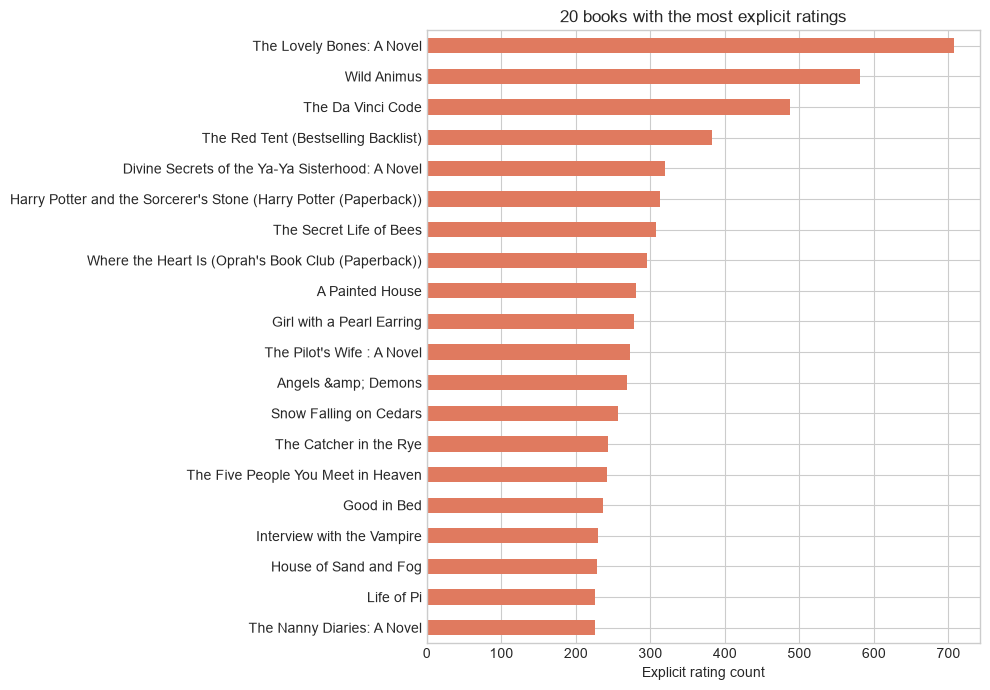

In [5]:
top_books = (
    books.set_index('book_id').join(explicit_book_activity)
    .dropna(subset=['explicit_rating_count'])
    .sort_values('explicit_rating_count', ascending=False)
    .head(20)
)
display(top_books[['title', 'authors', 'explicit_rating_count']])
top_books.sort_values('explicit_rating_count').plot.barh(
    y='explicit_rating_count', x='title', figsize=(10, 7), legend=False, color='#e07a5f'
)
plt.title('20 books with the most explicit ratings')
plt.xlabel('Explicit rating count')
plt.ylabel('')
plt.tight_layout()

## Catalog completeness and interaction sparsity

The catalog has metadata but no descriptions or categories in this dataset. Title, author, and publisher can support a basic text similarity baseline; richer content recommendations require another trustworthy metadata source. The matrix density is descriptive only and does not mean missing user-book pairs are negative feedback.

In [6]:
metadata_missing = books[['title', 'authors', 'publisher', 'publication_year']].isna().mean().sort_values(ascending=False)
display(metadata_missing.rename('missing_fraction').to_frame())

n_users = ratings['user_id'].nunique()
n_books = ratings['book_id'].nunique()
all_interaction_density = len(ratings) / (n_users * n_books)
explicit_rows = ratings.loc[ratings['is_explicit']]
explicit_density = len(explicit_rows) / (n_users * n_books)
summary = pd.Series({
    'users with interactions': n_users,
    'books with interactions': n_books,
    'all observed interactions': len(ratings),
    'explicit ratings': len(explicit_rows),
    'observed matrix density (all)': all_interaction_density,
    'observed matrix density (explicit)': explicit_density,
})
display(summary.to_frame('value'))

,missing_fraction
publication_year,0.000011
authors,0.000007
publisher,0.000007
title,0.000000


,value
users with interactions,9.210600e+04
books with interactions,2.701510e+05
all observed interactions,1.031139e+06
explicit ratings,3.838430e+05
observed matrix density (all),4.144028e-05
observed matrix density (explicit),1.542621e-05


## Modeling decisions to carry forward

- Preserve `is_explicit`; evaluate an explicit-rating model separately from an implicit-feedback model.
- Build popularity from explicit ratings with a confidence adjustment for rating count; evaluate interaction-count popularity as a separate candidate.
- Use a user-wise holdout for offline ranking evaluation because timestamps are absent. Document that this does not simulate future-time prediction.
- Start content features with title, author, and publisher. Do not join another catalog unless a reliable shared identifier is available.
- Keep all observed zero-rating rows available for the implicit-feedback experiment, but never interpret unobserved user-book pairs as confirmed negatives.

After running the notebook, record the key findings and chosen filters in the data/model documentation before training.